In [Can Uncertainty Be Programmable?](https://oponite.github.io/data-articles/website/can-uncertainty-be-programmable.html), Lana reasoned about values that I explicitly handed the program.

An obvious, consequential next question follows: **can Lana learn those values from data instead?**

To find out, I gave Lana a small machine-learning job: train a decision tree. Then I checked every answer against `scikit-learn`, Python's standard library for this kind of model.

## Lana's ML Capabilities

A decision tree learns a chain of yes/no questions from examples. To make a prediction, it follows those questions down to an answer. Every prediction has a path you can read; that path is why this model was the right first test for Lana.

This is the whole program for one comparison (the file path is shortened):

```Lana
import "std/trees" as trees
let data = resolve(result_value(json_parse(read_text("pima-42.json"))))
let result = trees.fit(data.task, data.train, data.holdout, {family: "tree", max_depth: 4, min_leaf: 2, ensemble_size: 1, seed: 42})
print(json_stringify(result.validation_report))
```

It loads the data, trains the tree, scores it on held-out rows and prints a report.

## The Data

I used two public datasets:

- **[Banknote Authentication](https://huggingface.co/datasets/farish07/banknote-authentication-dataset)**: 1,372 rows with 4 features measured from banknote images. The task is to label each note genuine or forged.
- **[Pima diabetes](https://huggingface.co/datasets/khoaguin/pima-indians-diabetes-database)**: 768 rows with 8 health measurements, such as glucose and BMI. The task is to predict the yes/no diabetes label.

For each dataset, I made two train/test splits. Each split used about 80% of the rows to train and 20% to test. Rows with identical feature values were always kept on the same side, so no test row was also a training row.

I tried two tree depths: **depth 4**, which allows a shorter chain of questions, and **depth 6**, which allows more detailed rules. Both got the same rows, feature order, depth and minimum leaf size.

Two datasets × two splits × two depths gives eight comparisons. The two splits share some rows, so the 1,712 predictions are counted per comparison, not as unique rows.

## Results

| Dataset | Split | Depth | Lana correct | scikit-learn correct | Different predictions |
|---|---:|---:|---:|---:|---:|
| Banknotes | 42 | 4 | 258 / 274 | 258 / 274 | 0 |
| Banknotes | 42 | 6 | 268 / 274 | 268 / 274 | 0 |
| Banknotes | 43 | 4 | 263 / 274 | 263 / 274 | 0 |
| Banknotes | 43 | 6 | 271 / 274 | 271 / 274 | 0 |
| Diabetes | 42 | 4 | 103 / 154 | 103 / 154 | 0 |
| Diabetes | 42 | 6 | 110 / 154 | 109 / 154 | 1 |
| Diabetes | 43 | 4 | 114 / 154 | 114 / 154 | 0 |
| Diabetes | 43 | 6 | 105 / 154 | 106 / 154 | 1 |

The tools agreed on **1,710 of 1,712** predictions. All the banknote predictions matched. Diabetes matched fully at depth 4 and differed by one prediction per split at depth 6. Lana was right on one of those two predictions and scikit-learn on the other.

Additionally, median program runtime and peak memory usage are captured. These cover starting the program, loading the data, training and predicting. Each comparison was measured three times after a warm-up.

| Dataset | Lana median time | scikit-learn median time | Lana peak memory | scikit-learn peak memory |
|---|---:|---:|---:|---:|
| Banknotes | 0.33–0.39 s | 0.55–0.56 s | ~48 MiB | ~124–125 MiB |
| Diabetes | 0.13–0.15 s | 0.55–0.57 s | ~41–42 MiB | ~124–125 MiB |

Each range covers the medians of the four comparisons for that dataset. Lana won every comparison on both time and memory.

`scikit-learn`'s numbers include starting Python and importing its libraries, so anyone who runs a model as a one-off command pays that cost every time.

***Lana's command-line tool doesn't have that overhead.***

To separate training from everything else, I trained on 200, 400, 600 and 800 banknote rows for just building the tree. I shuffled the rows with a fixed seed, and each larger set included the smaller ones. The tree depth stayed at 4, and the 274 test rows stayed the same.

| Training rows | Lana tree building | scikit-learn fit | Lana whole run | scikit-learn whole run |
|---:|---:|---:|---:|---:|
| 200 | 11.44 ms | 0.99 ms | 0.047 s | 0.563 s |
| 400 | 42.24 ms | 1.15 ms | 0.085 s | 0.552 s |
| 600 | 89.94 ms | 1.23 ms | 0.135 s | 0.556 s |
| 800 | 161.36 ms | 1.45 ms | 0.215 s | 0.557 s |

All values are medians of three runs after a warm-up. 

Here, `scikit-learn` builds the tree about 12× faster at 200 rows and about 110× faster at 800. When the rows grew 4×, Lana's build time grew about 14×. 

***Yet, Lana still finished every whole run first.*** Its peak memory went from `24.5 MB` at 200 rows to `39.4 MB` at 800, while scikit-learn stayed at about `124 MB`.

Predictions matched on all 274 test rows at 200, 400 and 800 training rows. At 600 rows, they differed by one: Lana got 259 right and scikit-learn 258. Across both experiments, that makes **3 disagreements in 2,808 predictions**.

The [appendix](#appendix-experiment-records) recomputes these tables and charts them from the saved records.

## Why This Matters

Lana now does more than calculate with values you give it. It takes real examples, learns a model and predicts on data it hasn't seen, and the predictions match `scikit-learn` at the tested scale.

The bigger idea is what happens next. A decision tree doesn't just give an answer; it gives the chain of questions that led there. Lana's tree interface can expose that chain. That fits naturally with Lana's information model, where a learned prediction would carry its evidence and uncertainty forward.

This experiment establishes the learning piece. Wiring it into the uncertainty model is the next piece.

## Appendix: experiment records

Everything below is computed from the saved records in `data/lana-tree-scale/`, not copied from the tables above.

In [ ]:
#| code-fold: true
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name in {"drafts", "website"} else Path.cwd()
RECORDS = REPO_ROOT / "data/lana-tree-scale"
COLORS = {"Lana": "#2a78d6", "scikit-learn": "#eb6834"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

def read_json(rel): return json.loads((RECORDS / rel).read_text())
def read_jsonl(rel): return [json.loads(l) for l in (RECORDS / rel).read_text().splitlines() if l.strip()]

perf = read_json("performance/summary.json")
perf_runs = read_jsonl("performance/measurements.jsonl")
perf_manifest = read_json("performance/manifest.json")
rows = read_json("row-count/summary.json")
rows_runs = read_jsonl("row-count/measurements.jsonl")
rows_manifest = read_json("row-count/manifest.json")

### A. Setup and integrity

The versions used, and a check that each saved input file still has the SHA-256 hash recorded at run time.

In [ ]:
#| code-fold: true
versions = pd.DataFrame(
    [(k, perf_manifest[k]) for k in ["lana_version", "sklearn_version", "python_version", "platform"]],
    columns=["Item", "Value"],
).set_index("Item")
display(versions)

def sha256(path): return hashlib.sha256(path.read_bytes()).hexdigest()

checks = []
for recorded_path, expected in perf_manifest["hashes"].items():
    # Records were made under /tmp/lana-tree-scale; the Lana binary lives outside the records.
    local = RECORDS / recorded_path.split("lana-tree-scale/", 1)[-1] if "lana-tree-scale/" in recorded_path else None
    status = ("match" if sha256(local) == expected else "MISMATCH") if local and local.exists() else "not in records"
    checks.append((Path(recorded_path).name, status))
src = RECORDS / rows_manifest["dataset_source"].split("lana-tree-scale/", 1)[-1]
checks.append((f"{src.name} (row-count source)", "match" if sha256(src) == rows_manifest["dataset_sha256"] else "MISMATCH"))
pd.DataFrame(checks, columns=["File", "Hash check"]).set_index("File")

,Value
Item,
lana_version,"Lana 4.2.0 (LABC v2, Rust VM, native compiler)"
sklearn_version,1.9.1
python_version,Python 3.15.2
platform,macOS-26.6-arm64-arm-64bit-Mach-O


,Hash check
File,
lana,not in records
baseline.py,match
banknote-42.json,match
banknote-43.json,match
pima-42.json,match
pima-43.json,match
banknote-42-d4.lana,match
banknote-42-d6.lana,match
banknote-43-d4.lana,match


### B. Agreement, recomputed

Correct counts and disagreements for each of the eight comparisons, read from `performance/summary.json`.

In [ ]:
#| code-fold: true
agreement = pd.DataFrame([{
    "Dataset": "Banknotes" if r["dataset"] == "banknote" else "Diabetes",
    "Split": r["seed"], "Depth": r["depth"],
    "Lana correct": f'{r["lana"]["correct"]} / {r["lana"]["count"]}',
    "scikit-learn correct": f'{r["sklearn"]["correct"]} / {r["sklearn"]["count"]}',
    "Different predictions": r["disagreements"],
} for r in perf])
total = sum(r["lana"]["count"] for r in perf)
print(f'Agreed on {total - agreement["Different predictions"].sum():,} of {total:,} predictions')
agreement

Agreed on 1,710 of 1,712 predictions


,Dataset,Split,Depth,Lana correct,scikit-learn correct,Different predictions
0,Banknotes,42,4,258 / 274,258 / 274,0
1,Banknotes,42,6,268 / 274,268 / 274,0
2,Banknotes,43,4,263 / 274,263 / 274,0
3,Banknotes,43,6,271 / 274,271 / 274,0
4,Diabetes,42,4,103 / 154,103 / 154,0
5,Diabetes,42,6,110 / 154,109 / 154,1
6,Diabetes,43,4,114 / 154,114 / 154,0
7,Diabetes,43,6,105 / 154,106 / 154,1


### C. The three disagreements

Every test row where Lana and scikit-learn predicted differently, from the first measured run of each comparison.

In [ ]:
#| code-fold: true
def first_measured(runs, **match):
    out = {}
    for r in runs:
        if r["phase"] == "measured" and all(r[k] == v for k, v in match.items()):
            out.setdefault(r["implementation"], r)
    return out

diffs = []
for r in perf:
    pair = first_measured(perf_runs, dataset=r["dataset"], split=r["seed"], depth=r["depth"])
    label = f'{"Banknote" if r["dataset"] == "banknote" else "Diabetes"} split {r["seed"]}, depth {r["depth"]}'
    sk = {p["id"]: p for p in pair["sklearn"]["predictions"]}
    for p in pair["lana"]["predictions"]:
        if p["prediction"] != sk[p["id"]]["prediction"]:
            diffs.append((label, p["id"], p["prediction"], sk[p["id"]]["prediction"], p["target"]))
for n in sorted({r["rows"] for r in rows}):
    pair = first_measured(rows_runs, rows=n)
    sk = {p["id"]: p for p in pair["sklearn"]["predictions"]}
    for p in pair["lana"]["predictions"]:
        if p["prediction"] != sk[p["id"]]["prediction"]:
            diffs.append((f"Banknote, {n} training rows, depth 4", p["id"], p["prediction"], sk[p["id"]]["prediction"], p["target"]))

pd.DataFrame(diffs, columns=["Experiment", "Row", "Lana", "scikit-learn", "True label"])

,Experiment,Row,Lana,scikit-learn,True label
0,"Diabetes split 42, depth 6",row-0294,False,True,False
1,"Diabetes split 43, depth 6",row-0507,True,False,False
2,"Banknote, 600 training rows, depth 4",row-0980,True,False,True


### D. Whole-run time and memory

Each dot is the median of three measured runs; the line through it spans the fastest and slowest run. Lower is better.

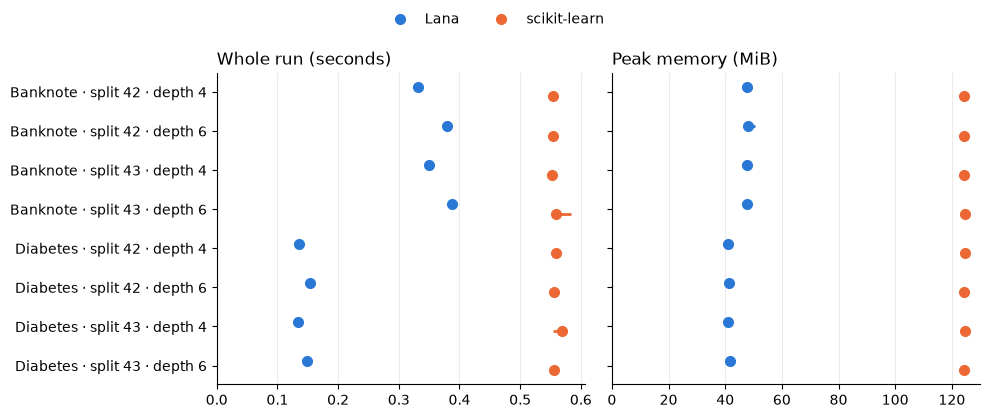

In [ ]:
#| code-fold: true
labels = [f'{"Banknote" if r["dataset"] == "banknote" else "Diabetes"} · split {r["seed"]} · depth {r["depth"]}' for r in perf]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
panels = [("time", "Whole run (seconds)", 1), ("rss", "Peak memory (MiB)", 1)]
for ax, (key, title, _) in zip(axes, panels):
    for offset, (name, impl) in zip([-0.12, 0.12], [("Lana", "lana"), ("scikit-learn", "sklearn")]):
        y = [i + offset for i in range(len(perf))]
        med = [r[impl][f"{key}_median"] for r in perf]
        lo = [r[impl][f"{key}_range"][0] for r in perf]
        hi = [r[impl][f"{key}_range"][1] for r in perf]
        ax.hlines(y, lo, hi, color=COLORS[name], linewidth=2)
        ax.plot(med, y, "o", color=COLORS[name], markersize=7, label=name)
    ax.set_title(title, loc="left")
    ax.set_xlim(left=0)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(perf)), labels)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

### E. Scaling with training rows

Banknote data, depth 4, the same 274 test rows throughout. The left chart uses a log scale, so equal vertical steps mean equal multiples.

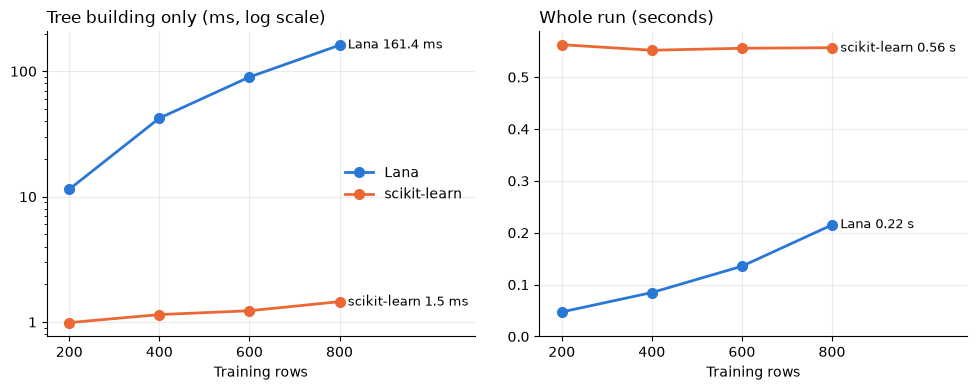

,scikit-learn builds faster by
Training rows,
200,12×
400,37×
600,73×
800,111×


In [ ]:
#| code-fold: true
by_impl = {name: sorted((r for r in rows if r["implementation"] == impl), key=lambda r: r["rows"])
           for name, impl in [("Lana", "lana"), ("scikit-learn", "sklearn")]}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, series in by_impl.items():
    n = [r["rows"] for r in series]
    build = [r["median_training_ms"] for r in series]
    whole = [r["median_whole_seconds"] for r in series]
    for ax, y, fmt in [(axes[0], build, "{:.1f} ms"), (axes[1], whole, "{:.2f} s")]:
        ax.plot(n, y, "-o", color=COLORS[name], linewidth=2, markersize=7, label=name)
        ax.annotate(f"{name} {fmt.format(y[-1])}", (n[-1], y[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
axes[0].set_title("Tree building only (ms, log scale)", loc="left")
axes[1].set_title("Whole run (seconds)", loc="left")
axes[1].set_ylim(bottom=0)
for ax in axes:
    ax.set_xticks([200, 400, 600, 800])
    ax.set_xlabel("Training rows")
    ax.set_xlim(150, 1100)
axes[0].legend(frameon=False, loc="center right")
fig.tight_layout()
plt.show()

ratio = pd.DataFrame({
    "Training rows": [r["rows"] for r in by_impl["Lana"]],
    "scikit-learn builds faster by": [f'{l["median_training_ms"] / s["median_training_ms"]:.0f}×'
                                      for l, s in zip(by_impl["Lana"], by_impl["scikit-learn"])],
}).set_index("Training rows")
ratio